# Clasificación de lesiones cutáneas (HAM10000) con cuatro arquitecturas preentrenadas: protocolo sin fuga de datos

**Curso:** Aprendizaje Automático I · USIL · **Grupo 01**  
**Revista objetivo:** *Bioengineering* (MDPI), ISSN 2306-5354  
**Notebook final.**

## Diseño

* **Cuatro algoritmos** (extractor congelado preentrenado en ImageNet + regresión logística multinomial): ResNet-50, DenseNet-201, ConvNeXt-Tiny, Swin-Tiny. Mismo preprocesamiento, mismo clasificador, misma rejilla de hiperparámetros, misma partición y misma métrica de selección (F1 macro).
* **Orden del protocolo (indicación del docente):** primero la partición (70 % entrenamiento / 30 % prueba) y recién después el balanceo, que ocurre solo dentro del entrenamiento. Se incluye además una línea base de clase mayoritaria, como en los ejemplos de clase.
* **Dos escenarios** sobre la misma partición: (A) sin balanceo y (B) con equilibrado por re-muestreo a `BAL_N` imágenes por clase **dentro del entrenamiento**.
* Los embeddings de una red **congelada** no se ajustan con los datos del estudio, por lo que extraerlos antes de particionar no introduce fuga; todo lo que sí aprende de los datos (escalado, remuestreo, clasificador) está dentro del pipeline.


## Parte A · Preparación y extracción de embeddings

### A.1 Datos y licencia (Anexo experimental, ítem 01)
* **Fuente:** HAM10000, Tschandl, Rosendahl y Kittler (2018), *Scientific Data* 5:180161, https://doi.org/10.1038/sdata.2018.161
* **Repositorio:** Harvard Dataverse, https://doi.org/10.7910/DVN/DBW86T (se descarga manualmente; `HAM10000_images_part_1.zip`, `HAM10000_images_part_2.zip` y `HAM10000_metadata`).
* **Licencia:** la ficha del repositorio indica CC BY-NC 4.0 — **verificar en la página del dataset antes de enviar**.
* Coloca en la carpeta de Drive indicada en `BASE_DRIVE` los `.zip` **o** las carpetas ya descomprimidas (`HAM10000_images_part_1/`, `HAM10000_images_part_2/`) y el archivo de metadatos (con o sin extensión `.csv`).

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import os
BASE_DRIVE = "/content/drive/MyDrive/usil/aprendizaje automatico/trabajo final"
DATA_DIR   = "/content/ham10000"
FEAT_DIR   = os.path.join(BASE_DRIVE, "features")
N_SUBSET   = None
SEED       = 42
BATCH_SIZE = 64
os.makedirs(FEAT_DIR, exist_ok=True)
FEATURES_FILE = os.path.join(FEAT_DIR, "features_ham10000.npz")
META_FILE     = os.path.join(FEAT_DIR, "meta_ham10000.csv")
print("Se guardará en:", FEATURES_FILE)

Se guardará en: /content/drive/MyDrive/usil/aprendizaje automatico/trabajo final/features/features_ham10000.npz


In [3]:

SKIP_A = os.path.exists(FEATURES_FILE) and os.path.exists(META_FILE)
print("SKIP_A =", SKIP_A)

SKIP_A = False


In [4]:
if not SKIP_A:
    from google.colab import drive
    if not os.path.isdir(BASE_DRIVE):
        try: drive.mount('/content/drive')
        except ValueError: drive.mount('/content/drive', force_remount=True)
    assert os.path.isdir(BASE_DRIVE), f"No existe BASE_DRIVE: {BASE_DRIVE}. Revisa la ruta (clic derecho > Copiar ruta en el panel de archivos)."
    import glob, subprocess
    zips = glob.glob(os.path.join(BASE_DRIVE, "*.zip"))
    print("ZIP encontrados (puede ser 0 si las imágenes ya están en carpetas):", zips)
    os.makedirs(DATA_DIR, exist_ok=True)
    for z in zips:
        subprocess.run(["unzip", "-q", "-n", z, "-d", DATA_DIR], check=True)

    IMAGE_ROOTS = [DATA_DIR, BASE_DRIVE]
    print("Carpetas en Drive:", [d for d in os.listdir(BASE_DRIVE)])
    csvs = glob.glob(os.path.join(BASE_DRIVE, "**", "HAM10000_metadata*"), recursive=True) + \
           glob.glob(os.path.join(DATA_DIR, "**", "HAM10000_metadata*"), recursive=True)
    print("Metadatos:", csvs)

ZIP encontrados (puede ser 0 si las imágenes ya están en carpetas): []
Carpetas en Drive: ['Experimentos_Final_Grupo01.ipynb', 'HAM10000_metadata', 'HAM10000_images_part_2', 'HAM10000_images_part_1', 'features']
Metadatos: ['/content/drive/MyDrive/usil/aprendizaje automatico/trabajo final/HAM10000_metadata']


In [5]:
if not SKIP_A:
    import subprocess, sys
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "timm"], check=True)

In [6]:
if not SKIP_A:
    import numpy as np, pandas as pd, cv2, torch, timm, time
    from PIL import Image
    from torch.utils.data import Dataset, DataLoader

    np.random.seed(SEED); torch.manual_seed(SEED)
    DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
    print("Dispositivo:", DEVICE)

    meta_path = [p for p in csvs if p.endswith(".csv") or "metadata" in p][0]
    meta = pd.read_csv(meta_path, sep=None, engine="python")
    paths = {}
    for base in IMAGE_ROOTS:
        for root, _, files in os.walk(base):
            for f in files:
                if f.lower().endswith(".jpg"): paths.setdefault(f[:-4], os.path.join(root, f))
    print("Imágenes .jpg encontradas:", len(paths))
    meta["path"] = meta["image_id"].map(paths)
    assert meta["path"].notna().all(), f"Faltan {int(meta['path'].isna().sum())} imágenes: revisa que estén las dos carpetas/zips (part_1 y part_2)"
    CLASSES = ["akiec","bcc","bkl","df","mel","nv","vasc"]
    meta["label"] = meta["dx"].map({c:i for i,c in enumerate(CLASSES)})
    if N_SUBSET:
        meta = meta.sample(N_SUBSET, random_state=SEED).reset_index(drop=True)
    print(meta.shape, meta["dx"].value_counts().to_dict())

Dispositivo: cuda
Imágenes .jpg encontradas: 10015
(10015, 10) {'nv': 6705, 'mel': 1113, 'bkl': 1099, 'bcc': 514, 'akiec': 327, 'vasc': 142, 'df': 115}


In [7]:
if not SKIP_A:

    def remove_hair_dullrazor(img_rgb):
        gray = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2GRAY)
        kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (9, 9))
        blackhat = cv2.morphologyEx(gray, cv2.MORPH_BLACKHAT, kernel)
        _, thresh = cv2.threshold(blackhat, 12, 255, cv2.THRESH_BINARY)
        bgr = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2BGR)
        return cv2.cvtColor(cv2.inpaint(bgr, thresh, 3, cv2.INPAINT_TELEA), cv2.COLOR_BGR2RGB)

    def enhance_contrast_agcwd(img_rgb, alpha=0.45):
        hsv = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2HSV); v = hsv[:, :, 2]
        hist, _ = np.histogram(v.flatten(), 256, [0, 256]); pdf = hist / v.size
        pdf_w = pdf.max() * ((pdf - pdf.min()) / (pdf.max() - pdf.min() + 1e-8)) ** alpha
        cdf_w = np.cumsum(pdf_w) / (np.sum(pdf_w) + 1e-8)
        lut = np.array([255 * ((i / 255.0) ** (1.0 - cdf_w[i])) for i in range(256)], dtype=np.uint8)
        hsv[:, :, 2] = cv2.LUT(v, lut)
        return cv2.cvtColor(hsv, cv2.COLOR_HSV2RGB)

    MEAN = torch.tensor([0.485, 0.456, 0.406]).view(3,1,1); STD = torch.tensor([0.229, 0.224, 0.225]).view(3,1,1)
    class DermDataset(Dataset):
        def __init__(self, df): self.p = df["path"].values
        def __len__(self): return len(self.p)
        def __getitem__(self, i):
            a = np.array(Image.open(self.p[i]).convert("RGB").resize((224, 224)))
            a = enhance_contrast_agcwd(remove_hair_dullrazor(a))
            t = torch.from_numpy(a).permute(2,0,1).float() / 255.0
            return (t - MEAN) / STD, i

    BACKBONES = {"ResNet-50": "resnet50", "DenseNet-201": "densenet201",
                 "ConvNeXt-Tiny": "convnext_tiny", "Swin-Tiny": "swin_tiny_patch4_window7_224"}
    nets = {k: timm.create_model(v, pretrained=True, num_classes=0).to(DEVICE).eval() for k, v in BACKBONES.items()}
    print({k: sum(p.numel() for p in m.parameters())/1e6 for k, m in nets.items()}, "(millones de parámetros)")

model.safetensors: reconstructing file:   0%|          |  0.00B /  102MB            

model.safetensors: downloading bytes:           |  0.00B            

model.safetensors: reconstructing file:   0%|          |  0.00B / 81.1MB            

model.safetensors: downloading bytes:           |  0.00B            

model.safetensors: reconstructing file:   0%|          |  0.00B /  114MB            

model.safetensors: downloading bytes:           |  0.00B            

model.safetensors: reconstructing file:   0%|          |  0.00B /  114MB            

model.safetensors: downloading bytes:           |  0.00B            

{'ResNet-50': 23.508032, 'DenseNet-201': 18.092928, 'ConvNeXt-Tiny': 27.820128, 'Swin-Tiny': 27.519354} (millones de parámetros)


In [8]:
if not SKIP_A:
    feats = {k: [] for k in BACKBONES}; order = []
    loader = DataLoader(DermDataset(meta), batch_size=BATCH_SIZE, shuffle=False, num_workers=2)
    t0 = time.time()
    with torch.no_grad():
        for b, (x, idx) in enumerate(loader):
            x = x.to(DEVICE)
            for k, m in nets.items(): feats[k].append(m(x).float().cpu().numpy())
            order.append(idx.numpy())
            if b % 20 == 0: print(f"lote {b}/{len(loader)}  {time.time()-t0:.0f}s")
    order = np.concatenate(order); assert (order == np.arange(len(meta))).all()
    arrays = {f"X_{k}": np.vstack(v).astype("float32") for k, v in feats.items()}
    np.savez_compressed(FEATURES_FILE, y=meta["label"].values, **arrays)
    meta.drop(columns=["path"]).to_csv(META_FILE, index=False)
    print("Guardado:", FEATURES_FILE, {k: v.shape for k, v in arrays.items()}, f"{time.time()-t0:.0f}s")

lote 0/157  187s
lote 20/157  439s
lote 40/157  737s
lote 60/157  980s
lote 80/157  1181s
lote 100/157  1395s
lote 120/157  1729s
lote 140/157  2004s
Guardado: /content/drive/MyDrive/usil/aprendizaje automatico/trabajo final/features/features_ham10000.npz {'X_ResNet-50': (10015, 2048), 'X_DenseNet-201': (10015, 1920), 'X_ConvNeXt-Tiny': (10015, 768), 'X_Swin-Tiny': (10015, 768)} 2229s


## Parte B · Exploración, partición, validación y evaluación


In [9]:
import os, sys, json, time, platform, warnings, zipfile, importlib.util, subprocess
for _pkg, _pip in [("imblearn", "imbalanced-learn"), ("statsmodels", "statsmodels")]:
    if importlib.util.find_spec(_pkg) is None: subprocess.run([sys.executable, "-m", "pip", "install", "-q", _pip], check=True)
from collections import Counter
import numpy as np, pandas as pd
import matplotlib; import matplotlib.pyplot as plt
import sklearn, scipy, imblearn, statsmodels
from sklearn.model_selection import StratifiedGroupKFold, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, precision_score, f1_score,
                             matthews_corrcoef, roc_auc_score, confusion_matrix, classification_report)
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.under_sampling import RandomUnderSampler
from imblearn.over_sampling import RandomOverSampler
from statsmodels.stats.contingency_tables import mcnemar
from statsmodels.stats.multitest import multipletests
warnings.filterwarnings("ignore")

FEATURES_FILE = globals().get("FEATURES_FILE", os.environ.get("HAM_FEATURES", "features_ham10000.npz"))
META_FILE     = globals().get("META_FILE",     os.environ.get("HAM_META",     "meta_ham10000.csv"))
OUT_DIR       = os.environ.get("HAM_OUT", os.path.join(os.path.dirname(FEATURES_FILE) or ".", "resultados_finales"))
for sub in ("tablas", "figuras"): os.makedirs(os.path.join(OUT_DIR, sub), exist_ok=True)

SEED = 42
CLASSES = ["akiec", "bcc", "bkl", "df", "mel", "nv", "vasc"]
MODELS  = ["ResNet-50", "DenseNet-201", "ConvNeXt-Tiny", "Swin-Tiny"]
SCENARIOS = {"A_sin_balanceo": False, "B_sobremuestreo_train": True}
TEST_N_FOLDS, TEST_USE_FOLDS = 10, 3
N_INNER   = 5
GRID_C    = [0.01, 0.1, 1.0, 10.0]
BAL_N     = 1000
SEEDS_ROBUST = [43, 44, 45, 46]
N_INNER_ROBUST = 3
N_BOOT    = 1000
N_JOBS    = -1
np.random.seed(SEED)

TRAZA = []
def traza(nombre, tipo, ref_manuscrito, ref_cuaderno): TRAZA.append(dict(artefacto=nombre, tipo=tipo, manuscrito=ref_manuscrito, cuaderno=ref_cuaderno))
def save_table(df, name, ms, nb, index=False):
    df.to_csv(os.path.join(OUT_DIR, "tablas", name), index=index); traza(f"tablas/{name}", "tabla", ms, nb); return df
def save_fig(fig, name, ms, nb):
    fig.savefig(os.path.join(OUT_DIR, "figuras", name), dpi=300, bbox_inches="tight"); traza(f"figuras/{name}", "figura", ms, nb)

ENTORNO = dict(python=sys.version.split()[0], plataforma=platform.platform(), cpu_count=os.cpu_count(),
               numpy=np.__version__, pandas=pd.__version__, scikit_learn=sklearn.__version__, imbalanced_learn=imblearn.__version__,
               scipy=scipy.__version__, statsmodels=statsmodels.__version__, matplotlib=matplotlib.__version__,
               semilla=SEED, cv_interna=N_INNER, rejilla_C=GRID_C, bal_n=BAL_N, n_boot=N_BOOT)
try:
    import torch, timm; ENTORNO.update(torch=torch.__version__, timm=timm.__version__, gpu=(torch.cuda.get_device_name(0) if torch.cuda.is_available() else None))
except Exception: pass
print(json.dumps(ENTORNO, indent=1, ensure_ascii=False))

{
 "python": "3.13.16",
 "plataforma": "Linux-6.6.159+-x86_64-with-glibc2.39",
 "cpu_count": 2,
 "numpy": "2.4.6",
 "pandas": "2.2.3",
 "scikit_learn": "1.6.1",
 "imbalanced_learn": "0.14.2",
 "scipy": "1.16.3",
 "statsmodels": "0.15.0",
 "matplotlib": "3.10.0",
 "semilla": 42,
 "cv_interna": 5,
 "rejilla_C": [
  0.01,
  0.1,
  1.0,
  10.0
 ],
 "bal_n": 1000,
 "n_boot": 1000,
 "torch": "2.14.1+cu130",
 "timm": "1.0.31",
 "gpu": "Tesla T4"
}


### B.1 Carga de embeddings y metadatos

In [10]:
Z = np.load(FEATURES_FILE, allow_pickle=False)
meta = pd.read_csv(META_FILE)
y = Z["y"].astype(int)
FEATS = {m: Z[f"X_{m}"] for m in MODELS}
groups = meta["lesion_id"].values
assert len(meta) == len(y) == len(groups) and all(len(v) == len(y) for v in FEATS.values())
assert (meta["dx"].map({c: i for i, c in enumerate(CLASSES)}).values == y).all(), "Etiquetas no coinciden con dx"
print({m: v.shape for m, v in FEATS.items()}, "| imágenes:", len(y), "| lesiones únicas:", len(np.unique(groups)))

{'ResNet-50': (10015, 2048), 'DenseNet-201': (10015, 1920), 'ConvNeXt-Tiny': (10015, 768), 'Swin-Tiny': (10015, 768)} | imágenes: 10015 | lesiones únicas: 7470


### B.2 Exploración y calidad de datos (Anexo, ítem 02)
Faltantes, duplicados, atípicos, distribución de clases y estructura por lesión. **La edad, el sexo y la localización no entran en ningún modelo** (solo imágenes), por lo que no se imputan.

,dx,n,porcentaje,lesiones_unicas
0,nv,6705,66.95,5403
1,mel,1113,11.11,614
2,bkl,1099,10.97,727
3,bcc,514,5.13,327
4,akiec,327,3.27,228
5,vasc,142,1.42,98
6,df,115,1.15,73


,indicador,valor
0,imágenes,10015.0
1,lesiones únicas,7470.0
2,image_id duplicados,0.0
3,lesiones con >1 imagen,1956.0
4,imágenes que pertenecen a lesiones con >1 imagen,4501.0
5,máx. imágenes por lesión,6.0
6,edad: mediana,50.0
7,edad: mín,0.0
8,edad: máx,85.0


,variable,faltantes,porc_faltantes,tipo
0,lesion_id,0,0.00,object
1,image_id,0,0.00,object
2,dx,0,0.00,object
3,dx_type,0,0.00,object
4,age,57,0.57,float64
5,sex,0,0.00,object
6,localization,0,0.00,object
7,dataset,0,0.00,object
8,label,0,0.00,int64


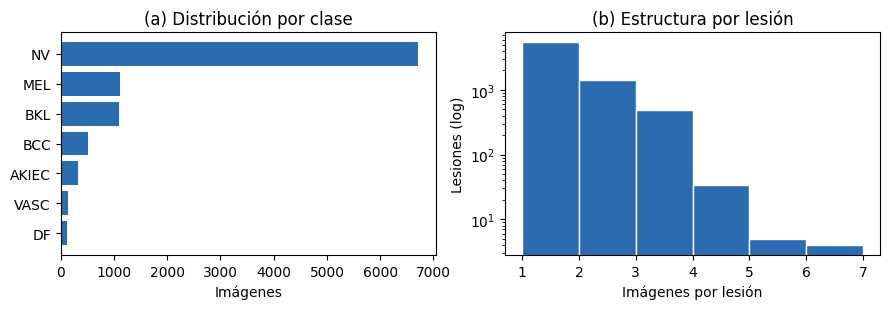

In [11]:
nb = "B.2 Exploración"
dist = meta["dx"].value_counts().rename_axis("dx").reset_index(name="n")
dist["porcentaje"] = (100 * dist["n"] / len(meta)).round(2)
dist["lesiones_unicas"] = dist["dx"].map(meta.groupby("dx")["lesion_id"].nunique())
save_table(dist, "tabla_distribucion_clases.csv", "Tabla 1", nb)

calidad = pd.DataFrame({
  "faltantes": meta.isna().sum(), "porc_faltantes": (100*meta.isna().mean()).round(2), "tipo": meta.dtypes.astype(str)}).rename_axis("variable").reset_index()
dup_img = int(meta["image_id"].duplicated().sum())
img_x_les = meta.groupby("lesion_id").size()
resumen_calidad = pd.DataFrame([
  ("imágenes", len(meta)), ("lesiones únicas", meta["lesion_id"].nunique()),
  ("image_id duplicados", dup_img), ("lesiones con >1 imagen", int((img_x_les > 1).sum())),
  ("imágenes que pertenecen a lesiones con >1 imagen", int(img_x_les[img_x_les > 1].sum())),
  ("máx. imágenes por lesión", int(img_x_les.max())),
  ("edad: mediana", float(meta["age"].median())), ("edad: mín", float(meta["age"].min())), ("edad: máx", float(meta["age"].max()))],
  columns=["indicador", "valor"])
save_table(calidad, "tabla_faltantes.csv", "Sección 2.2", nb)
save_table(resumen_calidad, "tabla_resumen_calidad.csv", "Sección 2.2", nb)
save_table(meta["dx_type"].value_counts().rename_axis("dx_type").reset_index(name="n"), "tabla_dx_type.csv", "Sección 2.1", nb)
display(dist); display(resumen_calidad); display(calidad)

fig, ax = plt.subplots(1, 2, figsize=(9, 3.2))
d = dist.sort_values("n"); ax[0].barh(d["dx"].str.upper(), d["n"], color="#2b6cb0"); ax[0].set_xlabel("Imágenes"); ax[0].set_title("(a) Distribución por clase")
ax[1].hist(img_x_les.values, bins=range(1, int(img_x_les.max()) + 2), color="#2b6cb0", edgecolor="white"); ax[1].set_yscale("log")
ax[1].set_xlabel("Imágenes por lesión"); ax[1].set_ylabel("Lesiones (log)"); ax[1].set_title("(b) Estructura por lesión")
plt.tight_layout(); save_fig(fig, "fig_exploracion.png", "Figura 2", nb); plt.show()

### B.3 Partición agrupada por lesión (Anexo, ítems 03 y 04)
`StratifiedGroupKFold(10)`: tres de diez pliegues (≈30 %) se reservan como **prueba** y no se tocan hasta la evaluación final. El ≈70 % restante es el único que se usa para validación cruzada y selección de hiperparámetros. Ninguna lesión aparece en ambos subconjuntos.

In [12]:
def outer_split(seed):
    sgkf = StratifiedGroupKFold(n_splits=TEST_N_FOLDS, shuffle=True, random_state=seed)
    te = np.sort(np.concatenate([t for k, (_, t) in zip(range(TEST_USE_FOLDS), sgkf.split(np.zeros(len(y)), y, groups))]))
    tr = np.setdiff1d(np.arange(len(y)), te)
    assert set(groups[tr]).isdisjoint(set(groups[te])), "FUGA: lesiones compartidas entre train y test"
    assert set(meta["image_id"].values[tr]).isdisjoint(set(meta["image_id"].values[te]))
    return tr, te

tr_idx, te_idx = outer_split(SEED)
part = pd.DataFrame({"conjunto": ["entrenamiento", "prueba"], "imagenes": [len(tr_idx), len(te_idx)],
                     "porcentaje": [round(100*len(tr_idx)/len(y), 1), round(100*len(te_idx)/len(y), 1)],
                     "lesiones": [len(np.unique(groups[tr_idx])), len(np.unique(groups[te_idx]))]})
conteo = pd.DataFrame({c: [int((y[tr_idx] == i).sum()), int((y[te_idx] == i).sum())] for i, c in enumerate(CLASSES)}, index=["entrenamiento", "prueba"]).T
conteo["%prueba"] = (100*conteo["prueba"]/(conteo["entrenamiento"]+conteo["prueba"])).round(1)
save_table(part, "tabla_particion.csv", "Tabla 2", "B.3 Partición")
save_table(conteo, "tabla_particion_por_clase.csv", "Tabla 2", "B.3 Partición", index=True)
display(part); display(conteo)
print("OK: sin lesiones ni imágenes compartidas entre entrenamiento y prueba. Semilla:", SEED)

,conjunto,imagenes,porcentaje,lesiones
0,entrenamiento,6985,69.7,5228
1,prueba,3030,30.3,2242


,entrenamiento,prueba,%prueba
akiec,212,115,35.2
bcc,340,174,33.9
bkl,792,307,27.9
df,96,19,16.5
mel,759,354,31.8
nv,4694,2011,30.0
vasc,92,50,35.2


OK: sin lesiones ni imágenes compartidas entre entrenamiento y prueba. Semilla: 42


### B.4 Definición del pipeline y de las métricas (Anexo, ítems 05 y 07)
Todo ajuste que aprende de los datos está **dentro** del pipeline: `StandardScaler` → (solo escenario B: submuestreo de clases con > `BAL_N` y sobremuestreo de clases con < `BAL_N`) → `LogisticRegression`. Dentro de `GridSearchCV`, el pipeline se vuelve a ajustar con los datos de entrenamiento de cada pliegue; el pliegue de validación nunca se remuestrea.

In [13]:
def make_pipe(balance, seed=SEED):
    steps = [("scaler", StandardScaler())]
    if balance:
        steps += [("under", RandomUnderSampler(sampling_strategy=lambda yy: {c: BAL_N for c, n in Counter(yy).items() if n > BAL_N}, random_state=seed)),
                  ("over",  RandomOverSampler(sampling_strategy=lambda yy: {c: BAL_N for c, n in Counter(yy).items() if n < BAL_N}, random_state=seed))]
    steps.append(("clf", LogisticRegression(max_iter=500, random_state=seed)))
    return ImbPipeline(steps)

def metrics(y_true, y_pred, y_prob):
    return {"accuracy": accuracy_score(y_true, y_pred),
            "balanced_acc(=recall macro)": balanced_accuracy_score(y_true, y_pred),
            "precision_macro": precision_score(y_true, y_pred, average="macro", zero_division=0),
            "f1_macro": f1_score(y_true, y_pred, average="macro", zero_division=0),
            "mcc": matthews_corrcoef(y_true, y_pred),
            "auc_ovr_macro": roc_auc_score(y_true, y_prob, multi_class="ovr", average="macro", labels=list(range(len(CLASSES))))}

SCORING = {"f1_macro": "f1_macro", "balanced_acc": "balanced_accuracy", "precision_macro": "precision_macro",
           "accuracy": "accuracy", "roc_auc": "roc_auc_ovr"}

def run_split(seed, n_inner, detail=False):
    tr, te = outer_split(seed)
    rows, store = [], {}
    # Línea base: clase mayoritaria (como en los ejemplos de clase)
    dum = DummyClassifier(strategy="prior").fit(FEATS[MODELS[0]][tr], y[tr]); pb = dum.predict_proba(FEATS[MODELS[0]][te]); pd_ = pb.argmax(1)
    rows.append(dict(semilla=seed, escenario="L_base", modelo="Línea base (clase mayoritaria)", **{f"test_{k}": v for k, v in metrics(y[te], pd_, pb).items()}))
    if detail: store[("L_base", "Línea base (clase mayoritaria)")] = dict(pred=pd_, prob=pb, cv_results=None, best_C=np.nan)
    for scen, bal in SCENARIOS.items():
        for m in MODELS:
            X = FEATS[m]
            cv = StratifiedGroupKFold(n_splits=n_inner, shuffle=True, random_state=seed)
            gs = GridSearchCV(make_pipe(bal, seed), {"clf__C": GRID_C}, scoring=SCORING, refit="f1_macro", cv=cv,
                              n_jobs=N_JOBS, return_train_score=True)
            t0 = time.time(); gs.fit(X[tr], y[tr], groups=groups[tr]); dt = time.time() - t0
            i = gs.best_index_; r = gs.cv_results_
            prob = gs.predict_proba(X[te]); pred = prob.argmax(1)
            prob_tr = gs.predict_proba(X[tr])
            row = dict(semilla=seed, escenario=scen, modelo=m, C=gs.best_params_["clf__C"],
                       f1_cv=r["mean_test_f1_macro"][i], f1_cv_sd=r["std_test_f1_macro"][i], f1_train_en_pliegues=r["mean_train_f1_macro"][i],
                       **{f"cv_{k}": f"{r[f'mean_test_{k}'][i]:.3f} ± {r[f'std_test_{k}'][i]:.3f}" for k in SCORING},
                       f1_train_completo=f1_score(y[tr], prob_tr.argmax(1), average="macro"), segundos=round(dt, 1),
                       **{f"test_{k}": v for k, v in metrics(y[te], pred, prob).items()})
            rows.append(row)
            if detail: store[(scen, m)] = dict(pred=pred, prob=prob, cv_results=pd.DataFrame(r), best_C=row["C"])
            print(f"[semilla {seed}] {scen:22s} {m:14s} C={row['C']:<5} F1cv={row['f1_cv']:.3f}  F1test={row['test_f1_macro']:.3f}  ({dt:.0f}s)")
    return pd.DataFrame(rows), store, tr, te

### B.5 Control de ausencia de fuga: etiquetas permutadas
Si el pipeline no filtra información de la prueba, entrenar con etiquetas de entrenamiento barajadas debe dar un desempeño cercano al azar (F1 macro ≈ 0.14 en 7 clases).

In [14]:
rng = np.random.default_rng(SEED)
ctrl = []
for scen, bal in SCENARIOS.items():
    y_perm = rng.permutation(y[tr_idx])
    p = make_pipe(bal).set_params(clf__C=0.1).fit(FEATS["DenseNet-201"][tr_idx], y_perm)
    pr = p.predict(FEATS["DenseNet-201"][te_idx])
    ctrl.append(dict(escenario=scen, f1_macro_test_etiquetas_permutadas=round(f1_score(y[te_idx], pr, average="macro"), 3),
                     accuracy=round(accuracy_score(y[te_idx], pr), 3), azar_esperado_f1_macro="≈0.14"))
ctrl = save_table(pd.DataFrame(ctrl), "tabla_control_permutacion.csv", "Sección 3.5 / Anexo", "B.5 Control de fuga"); display(ctrl)

,escenario,f1_macro_test_etiquetas_permutadas,accuracy,azar_esperado_f1_macro
0,A_sin_balanceo,0.147,0.527,≈0.14
1,B_sobremuestreo_train,0.116,0.246,≈0.14


### B.6 Experimento principal (semilla 42): validación cruzada agrupada, selección de C y evaluación en prueba


In [15]:
res_main, STORE, tr_idx, te_idx = run_split(SEED, N_INNER, detail=True)
res_main.to_csv(os.path.join(OUT_DIR, "tablas", "tabla_resultados_semilla42_completa.csv"), index=False)
traza("tablas/tabla_resultados_semilla42_completa.csv", "tabla", "Tablas 3-4", "B.6 Experimento principal")

[semilla 42] A_sin_balanceo         ResNet-50      C=0.01  F1cv=0.461  F1test=0.513  (174s)
[semilla 42] A_sin_balanceo         DenseNet-201   C=0.01  F1cv=0.562  F1test=0.618  (214s)
[semilla 42] A_sin_balanceo         ConvNeXt-Tiny  C=0.01  F1cv=0.520  F1test=0.555  (125s)
[semilla 42] A_sin_balanceo         Swin-Tiny      C=0.01  F1cv=0.527  F1test=0.554  (129s)
[semilla 42] B_sobremuestreo_train  ResNet-50      C=0.01  F1cv=0.445  F1test=0.485  (161s)
[semilla 42] B_sobremuestreo_train  DenseNet-201   C=0.01  F1cv=0.538  F1test=0.589  (232s)
[semilla 42] B_sobremuestreo_train  ConvNeXt-Tiny  C=0.01  F1cv=0.495  F1test=0.537  (104s)
[semilla 42] B_sobremuestreo_train  Swin-Tiny      C=0.01  F1cv=0.507  F1test=0.526  (116s)


### B.7 Resultados de validación cruzada y prueba (Tablas del manuscrito)

In [16]:
nb = "B.7 Tablas"
res_alg = res_main[res_main.escenario.isin(SCENARIOS)]
tcv = res_alg[["escenario", "modelo", "C"] + [f"cv_{k}" for k in SCORING]]
save_table(tcv, "tabla_validacion_cruzada.csv", "Tabla 3 (validación cruzada, media ± DE)", nb); display(tcv)
cols_cv = ["escenario", "modelo", "C", "f1_cv", "f1_cv_sd", "f1_train_en_pliegues", "f1_train_completo", "test_f1_macro"]
t_cv = res_alg[cols_cv].copy()
t_cv["brecha_train_cv"] = (t_cv["f1_train_en_pliegues"] - t_cv["f1_cv"]).round(3)
t_cv["brecha_cv_test"]  = (t_cv["f1_cv"] - t_cv["test_f1_macro"]).round(3)
save_table(t_cv.round(3), "tabla_validacion_y_sobreajuste.csv", "Tabla 3 / interpretación de sobreajuste", nb); display(t_cv.round(3))

tcols = ["escenario", "modelo", "test_accuracy", "test_balanced_acc(=recall macro)", "test_precision_macro", "test_f1_macro", "test_mcc", "test_auc_ovr_macro"]
t_test = res_main[tcols].copy().round(3)
save_table(t_test, "tabla_prueba_cuatro_modelos.csv", "Tabla 4", nb); display(t_test)

hip = pd.DataFrame([dict(escenario=k[0], modelo=k[1], mejor_C=v["best_C"], espacio_busqueda=str(GRID_C), metodo="GridSearchCV", metrica_objetivo="f1_macro",
                          validacion=f"StratifiedGroupKFold({N_INNER}) agrupada por lesion_id", ensayos=len(GRID_C)*N_INNER) for k, v in STORE.items()])
save_table(hip, "tabla_hiperparametros.csv", "Tabla 3 / Anexo ítem 06", nb)

,escenario,modelo,C,cv_f1_macro,cv_balanced_acc,cv_precision_macro,cv_accuracy,cv_roc_auc
1,A_sin_balanceo,ResNet-50,0.01,0.461 ± 0.021,0.426 ± 0.017,0.543 ± 0.048,0.742 ± 0.012,0.895 ± 0.006
2,A_sin_balanceo,DenseNet-201,0.01,0.562 ± 0.012,0.528 ± 0.018,0.639 ± 0.034,0.778 ± 0.010,0.937 ± 0.005
3,A_sin_balanceo,ConvNeXt-Tiny,0.01,0.520 ± 0.010,0.482 ± 0.020,0.613 ± 0.025,0.768 ± 0.011,0.926 ± 0.004
4,A_sin_balanceo,Swin-Tiny,0.01,0.527 ± 0.027,0.497 ± 0.032,0.605 ± 0.034,0.776 ± 0.006,0.932 ± 0.005
5,B_sobremuestreo_train,ResNet-50,0.01,0.445 ± 0.019,0.489 ± 0.024,0.424 ± 0.016,0.656 ± 0.010,0.879 ± 0.009
6,B_sobremuestreo_train,DenseNet-201,0.01,0.538 ± 0.017,0.597 ± 0.019,0.508 ± 0.017,0.708 ± 0.005,0.923 ± 0.006
7,B_sobremuestreo_train,ConvNeXt-Tiny,0.01,0.495 ± 0.015,0.583 ± 0.018,0.454 ± 0.018,0.681 ± 0.012,0.905 ± 0.007
8,B_sobremuestreo_train,Swin-Tiny,0.01,0.507 ± 0.012,0.590 ± 0.025,0.465 ± 0.012,0.682 ± 0.004,0.915 ± 0.005


,escenario,modelo,C,f1_cv,f1_cv_sd,f1_train_en_pliegues,f1_train_completo,test_f1_macro,brecha_train_cv,brecha_cv_test
1,A_sin_balanceo,ResNet-50,0.01,0.461,0.021,0.949,0.938,0.513,0.487,-0.051
2,A_sin_balanceo,DenseNet-201,0.01,0.562,0.012,0.944,0.930,0.618,0.381,-0.056
3,A_sin_balanceo,ConvNeXt-Tiny,0.01,0.520,0.010,0.784,0.771,0.555,0.264,-0.034
4,A_sin_balanceo,Swin-Tiny,0.01,0.527,0.027,0.784,0.762,0.554,0.256,-0.027
5,B_sobremuestreo_train,ResNet-50,0.01,0.445,0.019,0.860,0.839,0.485,0.415,-0.040
6,B_sobremuestreo_train,DenseNet-201,0.01,0.538,0.017,0.872,0.856,0.589,0.334,-0.051
7,B_sobremuestreo_train,ConvNeXt-Tiny,0.01,0.495,0.015,0.761,0.729,0.537,0.265,-0.041
8,B_sobremuestreo_train,Swin-Tiny,0.01,0.507,0.012,0.759,0.732,0.526,0.252,-0.018


,escenario,modelo,test_accuracy,test_balanced_acc(=recall macro),test_precision_macro,test_f1_macro,test_mcc,test_auc_ovr_macro
0,L_base,Línea base (clase mayoritaria),0.664,0.143,0.095,0.114,0.000,0.500
1,A_sin_balanceo,ResNet-50,0.736,0.472,0.595,0.513,0.480,0.903
2,A_sin_balanceo,DenseNet-201,0.784,0.578,0.684,0.618,0.573,0.944
3,A_sin_balanceo,ConvNeXt-Tiny,0.776,0.507,0.643,0.555,0.552,0.933
4,A_sin_balanceo,Swin-Tiny,0.770,0.529,0.605,0.554,0.541,0.935
5,B_sobremuestreo_train,ResNet-50,0.650,0.546,0.470,0.485,0.441,0.883
6,B_sobremuestreo_train,DenseNet-201,0.721,0.670,0.552,0.589,0.540,0.933
7,B_sobremuestreo_train,ConvNeXt-Tiny,0.692,0.639,0.495,0.537,0.505,0.918
8,B_sobremuestreo_train,Swin-Tiny,0.691,0.631,0.487,0.526,0.516,0.918


,escenario,modelo,mejor_C,espacio_busqueda,metodo,metrica_objetivo,validacion,ensayos
0,L_base,Línea base (clase mayoritaria),NaN,"[0.01, 0.1, 1.0, 10.0]",GridSearchCV,f1_macro,StratifiedGroupKFold(5) agrupada por lesion_id,20
1,A_sin_balanceo,ResNet-50,0.01,"[0.01, 0.1, 1.0, 10.0]",GridSearchCV,f1_macro,StratifiedGroupKFold(5) agrupada por lesion_id,20
2,A_sin_balanceo,DenseNet-201,0.01,"[0.01, 0.1, 1.0, 10.0]",GridSearchCV,f1_macro,StratifiedGroupKFold(5) agrupada por lesion_id,20
3,A_sin_balanceo,ConvNeXt-Tiny,0.01,"[0.01, 0.1, 1.0, 10.0]",GridSearchCV,f1_macro,StratifiedGroupKFold(5) agrupada por lesion_id,20
4,A_sin_balanceo,Swin-Tiny,0.01,"[0.01, 0.1, 1.0, 10.0]",GridSearchCV,f1_macro,StratifiedGroupKFold(5) agrupada por lesion_id,20
5,B_sobremuestreo_train,ResNet-50,0.01,"[0.01, 0.1, 1.0, 10.0]",GridSearchCV,f1_macro,StratifiedGroupKFold(5) agrupada por lesion_id,20
6,B_sobremuestreo_train,DenseNet-201,0.01,"[0.01, 0.1, 1.0, 10.0]",GridSearchCV,f1_macro,StratifiedGroupKFold(5) agrupada por lesion_id,20
7,B_sobremuestreo_train,ConvNeXt-Tiny,0.01,"[0.01, 0.1, 1.0, 10.0]",GridSearchCV,f1_macro,StratifiedGroupKFold(5) agrupada por lesion_id,20
8,B_sobremuestreo_train,Swin-Tiny,0.01,"[0.01, 0.1, 1.0, 10.0]",GridSearchCV,f1_macro,StratifiedGroupKFold(5) agrupada por lesion_id,20


### B.8 Incertidumbre: bootstrap por lesión (IC 95 %) y pruebas estadísticas pareadas

In [17]:
nb = "B.8 Incertidumbre"
yt, gt = y[te_idx], groups[te_idx]
lesion_ids = np.unique(gt); pos = pd.Series(np.arange(len(yt))).groupby(gt).apply(np.asarray).to_dict()
rng = np.random.default_rng(SEED)
BOOT = [np.concatenate([pos[l] for l in rng.choice(lesion_ids, len(lesion_ids))]) for _ in range(N_BOOT)]   # mismas remuestras para todos los modelos (pareado)

def boot_metric(pred, fn): return np.array([fn(yt[b], pred[b]) for b in BOOT])
FN = {"f1_macro": lambda a, p: f1_score(a, p, average="macro", zero_division=0), "mcc": matthews_corrcoef,
      "balanced_acc": balanced_accuracy_score, "accuracy": accuracy_score}
BOOTV = {}
ci_rows = []
for (scen, m), v in STORE.items():
    for k, fn in FN.items():
        b = boot_metric(v["pred"], fn); BOOTV[(scen, m, k)] = b
        ci_rows.append(dict(escenario=scen, modelo=m, metrica=k, estimado=fn(yt, v["pred"]), ic95_inf=np.percentile(b, 2.5), ic95_sup=np.percentile(b, 97.5)))
t_ci = save_table(pd.DataFrame(ci_rows).round(3), "tabla_intervalos_confianza.csv", "Tabla 4 (IC 95 %)", nb)
display(t_ci[t_ci.metrica == "f1_macro"])

# McNemar exacto por pares (aciertos/errores en la misma prueba), con corrección de Holm por escenario
mc_rows = []
for scen in SCENARIOS:
    pares, pv = [], []
    for i in range(len(MODELS)):
        for j in range(i+1, len(MODELS)):
            a = STORE[(scen, MODELS[i])]["pred"] == yt; b = STORE[(scen, MODELS[j])]["pred"] == yt
            n01, n10 = int((~a & b).sum()), int((a & ~b).sum())
            p = mcnemar([[int((a & b).sum()), n10], [n01, int((~a & ~b).sum())]], exact=True).pvalue
            pares.append((MODELS[i], MODELS[j], n10, n01)); pv.append(p)
    adj = multipletests(pv, method="holm")[1]
    for (mi, mj, n10, n01), p, pa in zip(pares, pv, adj):
        mc_rows.append(dict(escenario=scen, modelo_A=mi, modelo_B=mj, solo_A_acierta=n10, solo_B_acierta=n01, p_mcnemar=p, p_holm=pa, significativo_0_05=bool(pa < 0.05)))
t_mc = save_table(pd.DataFrame(mc_rows).round(4), "tabla_mcnemar.csv", "Sección 3.3", nb); display(t_mc)

# Efecto del balanceo sobre la MISMA prueba (diferencia pareada B - A, IC por bootstrap)
dif_rows = []
for m in MODELS:
    for k in ("f1_macro", "balanced_acc", "mcc", "accuracy"):
        d = BOOTV[("B_sobremuestreo_train", m, k)] - BOOTV[("A_sin_balanceo", m, k)]
        est = FN[k](yt, STORE[("B_sobremuestreo_train", m)]["pred"]) - FN[k](yt, STORE[("A_sin_balanceo", m)]["pred"])
        dif_rows.append(dict(modelo=m, metrica=k, diferencia_B_menos_A=est, ic95_inf=np.percentile(d, 2.5), ic95_sup=np.percentile(d, 97.5)))
t_dif = save_table(pd.DataFrame(dif_rows).round(3), "tabla_efecto_balanceo.csv", "Tabla 5", nb); display(t_dif)

,escenario,modelo,metrica,estimado,ic95_inf,ic95_sup
0,L_base,Línea base (clase mayoritaria),f1_macro,0.114,0.112,0.116
4,A_sin_balanceo,ResNet-50,f1_macro,0.513,0.469,0.556
8,A_sin_balanceo,DenseNet-201,f1_macro,0.618,0.576,0.656
12,A_sin_balanceo,ConvNeXt-Tiny,f1_macro,0.555,0.507,0.595
16,A_sin_balanceo,Swin-Tiny,f1_macro,0.554,0.513,0.599
20,B_sobremuestreo_train,ResNet-50,f1_macro,0.485,0.447,0.522
24,B_sobremuestreo_train,DenseNet-201,f1_macro,0.589,0.551,0.623
28,B_sobremuestreo_train,ConvNeXt-Tiny,f1_macro,0.537,0.503,0.570
32,B_sobremuestreo_train,Swin-Tiny,f1_macro,0.526,0.491,0.559


,escenario,modelo_A,modelo_B,solo_A_acierta,solo_B_acierta,p_mcnemar,p_holm,significativo_0_05
0,A_sin_balanceo,ResNet-50,DenseNet-201,192,337,0.0000,0.0000,True
1,A_sin_balanceo,ResNet-50,ConvNeXt-Tiny,191,313,0.0000,0.0000,True
2,A_sin_balanceo,ResNet-50,Swin-Tiny,218,320,0.0000,0.0001,True
3,A_sin_balanceo,DenseNet-201,ConvNeXt-Tiny,225,202,0.2870,0.5740,False
4,A_sin_balanceo,DenseNet-201,Swin-Tiny,251,208,0.0498,0.1495,False
5,A_sin_balanceo,ConvNeXt-Tiny,Swin-Tiny,209,189,0.3409,0.5740,False
6,B_sobremuestreo_train,ResNet-50,DenseNet-201,241,455,0.0000,0.0000,True
7,B_sobremuestreo_train,ResNet-50,ConvNeXt-Tiny,291,417,0.0000,0.0000,True
8,B_sobremuestreo_train,ResNet-50,Swin-Tiny,317,441,0.0000,0.0000,True
9,B_sobremuestreo_train,DenseNet-201,ConvNeXt-Tiny,373,285,0.0007,0.0014,True


,modelo,metrica,diferencia_B_menos_A,ic95_inf,ic95_sup
0,ResNet-50,f1_macro,-0.028,-0.064,0.006
1,ResNet-50,balanced_acc,0.074,0.037,0.111
2,ResNet-50,mcc,-0.039,-0.064,-0.015
3,ResNet-50,accuracy,-0.086,-0.102,-0.070
4,DenseNet-201,f1_macro,-0.029,-0.068,0.005
5,DenseNet-201,balanced_acc,0.093,0.056,0.128
6,DenseNet-201,mcc,-0.033,-0.058,-0.009
7,DenseNet-201,accuracy,-0.063,-0.079,-0.048
8,ConvNeXt-Tiny,f1_macro,-0.018,-0.055,0.018
9,ConvNeXt-Tiny,balanced_acc,0.132,0.099,0.165


### B.9 Matrices de confusión, métricas por clase y comparación gráfica

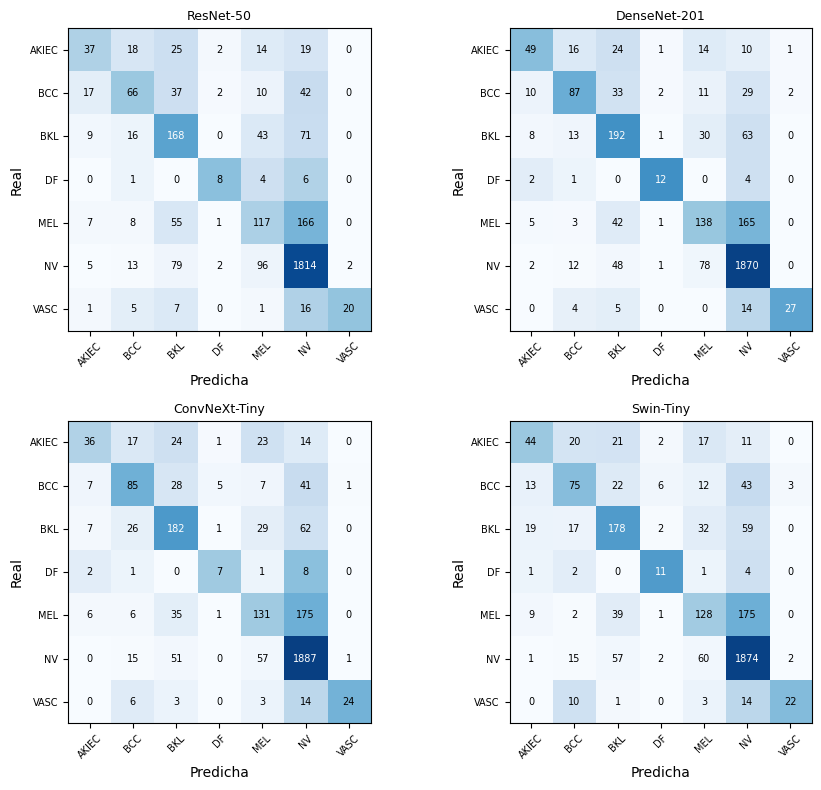

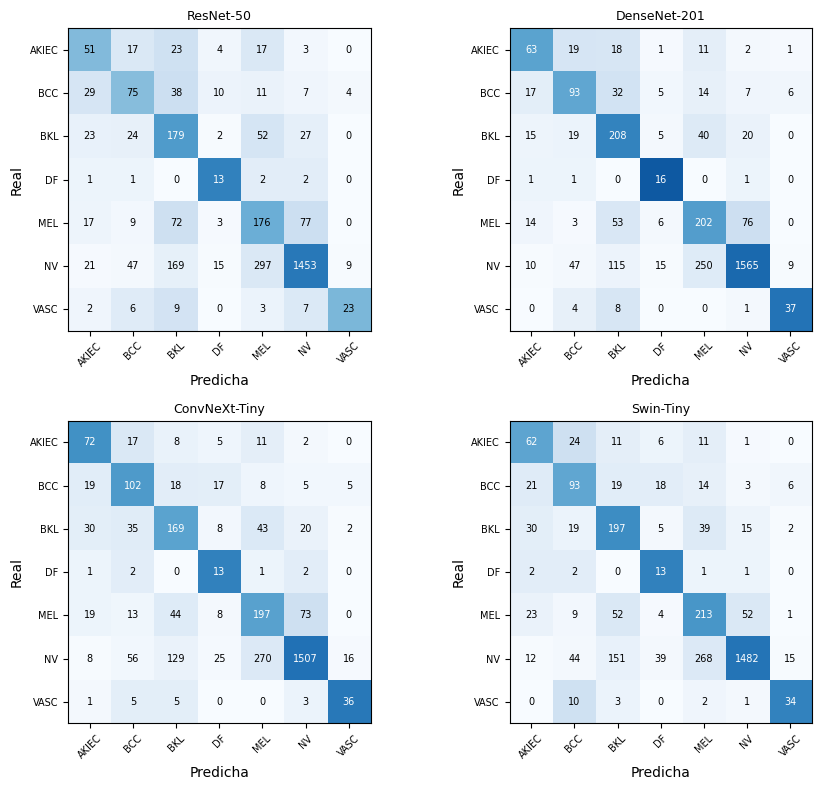

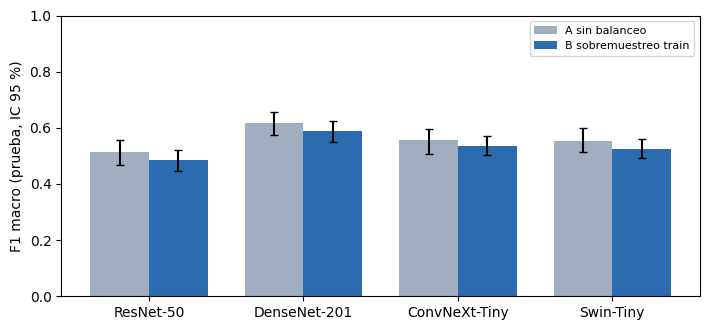

In [18]:
nb = "B.9 Figuras"
labels = [c.upper() for c in CLASSES]
def cm_fig(scen, fname, ref):
    fig, axs = plt.subplots(2, 2, figsize=(9.2, 8))
    for ax, m in zip(axs.ravel(), MODELS):
        cm = confusion_matrix(yt, STORE[(scen, m)]["pred"], labels=range(7)); cmn = cm / cm.sum(1, keepdims=True)
        ax.imshow(cmn, cmap="Blues", vmin=0, vmax=1)
        for i in range(7):
            for j in range(7): ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=7, color="white" if cmn[i, j] > .5 else "black")
        ax.set_xticks(range(7)); ax.set_xticklabels(labels, rotation=45, fontsize=7); ax.set_yticks(range(7)); ax.set_yticklabels(labels, fontsize=7)
        ax.set_title(m, fontsize=9); ax.set_xlabel("Predicha"); ax.set_ylabel("Real")
    plt.tight_layout(); save_fig(fig, fname, ref, nb); plt.show()
cm_fig("A_sin_balanceo", "fig_cm_sin_balanceo.png", "Figura 3")
cm_fig("B_sobremuestreo_train", "fig_cm_sobremuestreo.png", "Figura 4")

pc = []
for (scen, m), v in STORE.items():
    rep = classification_report(yt, v["pred"], target_names=CLASSES, output_dict=True, zero_division=0)
    for c in CLASSES: pc.append(dict(escenario=scen, modelo=m, clase=c, precision=rep[c]["precision"], recall=rep[c]["recall"], f1=rep[c]["f1-score"], soporte=int(rep[c]["support"])))
t_pc = save_table(pd.DataFrame(pc).round(3), "tabla_metricas_por_clase.csv", "Tabla 6 / análisis de errores", nb)

# Análisis de errores: confusiones más frecuentes del mejor modelo de cada escenario (por F1 macro en validación cruzada)
conf_rows = []
for scen in SCENARIOS:
    best_m = res_main[res_main.escenario == scen].sort_values("f1_cv", ascending=False).iloc[0]["modelo"]
    cm = confusion_matrix(yt, STORE[(scen, best_m)]["pred"], labels=range(7)); np.fill_diagonal(cm, 0)
    for flat in np.argsort(cm, axis=None)[::-1][:6]:
        i, j = divmod(int(flat), 7); conf_rows.append(dict(escenario=scen, modelo=best_m, real=CLASSES[i], predicha=CLASSES[j], casos=int(cm[i, j])))
save_table(pd.DataFrame(conf_rows), "tabla_confusiones_principales.csv", "Sección 3.4 (análisis de errores)", nb)

# Comparación F1 macro con IC
fig, ax = plt.subplots(figsize=(7.2, 3.4)); w = 0.38
for k, (scen, col) in enumerate(zip(SCENARIOS, ["#a0aec0", "#2b6cb0"])):
    sub = t_ci[(t_ci.escenario == scen) & (t_ci.metrica == "f1_macro")].set_index("modelo").loc[MODELS]
    ax.bar(np.arange(4) + (k-.5)*w, sub["estimado"], w, color=col, label=scen.replace("_", " "),
           yerr=[sub["estimado"]-sub["ic95_inf"], sub["ic95_sup"]-sub["estimado"]], capsize=3)
ax.set_xticks(range(4)); ax.set_xticklabels(MODELS); ax.set_ylabel("F1 macro (prueba, IC 95 %)"); ax.legend(fontsize=8); ax.set_ylim(0, 1)
plt.tight_layout(); save_fig(fig, "fig_comparacion_f1.png", "Figura 5", nb); plt.show()

### B.10 Robustez: otras semillas de partición (Anexo, ítem 09)
Se repite **todo el proceso** (partición agrupada, validación cruzada, selección de C y evaluación) con semillas distintas.

In [19]:
nb = "B.10 Robustez"
allres = [res_main]
for s in SEEDS_ROBUST:
    r, _, _, _ = run_split(s, N_INNER_ROBUST); allres.append(r)
R = pd.concat(allres, ignore_index=True)
R.to_csv(os.path.join(OUT_DIR, "tablas", "tabla_semillas_completa.csv"), index=False); traza("tablas/tabla_semillas_completa.csv", "tabla", "Anexo", nb)
if len(allres) > 1:
    agg = R.groupby(["escenario", "modelo"])[["test_f1_macro", "test_mcc", "test_balanced_acc(=recall macro)", "test_accuracy"]].agg(["mean", "std"]).round(3)
    agg.columns = ["_".join(c) for c in agg.columns]; agg = agg.reset_index(); agg["n_semillas"] = len(allres)
    save_table(agg, "tabla_robustez_semillas.csv", "Tabla 7", nb); display(agg)
else:
    print("Robustez omitida.")

[semilla 43] A_sin_balanceo         ResNet-50      C=0.01  F1cv=0.460  F1test=0.507  (92s)
[semilla 43] A_sin_balanceo         DenseNet-201   C=0.01  F1cv=0.564  F1test=0.605  (128s)
[semilla 43] A_sin_balanceo         ConvNeXt-Tiny  C=0.01  F1cv=0.499  F1test=0.538  (62s)
[semilla 43] A_sin_balanceo         Swin-Tiny      C=0.01  F1cv=0.524  F1test=0.583  (70s)
[semilla 43] B_sobremuestreo_train  ResNet-50      C=0.01  F1cv=0.463  F1test=0.480  (105s)
[semilla 43] B_sobremuestreo_train  DenseNet-201   C=0.01  F1cv=0.560  F1test=0.574  (149s)
[semilla 43] B_sobremuestreo_train  ConvNeXt-Tiny  C=0.01  F1cv=0.493  F1test=0.526  (61s)
[semilla 43] B_sobremuestreo_train  Swin-Tiny      C=0.01  F1cv=0.513  F1test=0.550  (69s)
[semilla 44] A_sin_balanceo         ResNet-50      C=0.01  F1cv=0.457  F1test=0.485  (80s)
[semilla 44] A_sin_balanceo         DenseNet-201   C=0.01  F1cv=0.559  F1test=0.616  (133s)
[semilla 44] A_sin_balanceo         ConvNeXt-Tiny  C=0.01  F1cv=0.495  F1test=0.546  (

,escenario,modelo,test_f1_macro_mean,test_f1_macro_std,test_mcc_mean,test_mcc_std,test_balanced_acc(=recall macro)_mean,test_balanced_acc(=recall macro)_std,test_accuracy_mean,test_accuracy_std,n_semillas
0,A_sin_balanceo,ConvNeXt-Tiny,0.539,0.012,0.539,0.014,0.495,0.010,0.771,0.005,5
1,A_sin_balanceo,DenseNet-201,0.604,0.014,0.572,0.019,0.558,0.017,0.785,0.011,5
2,A_sin_balanceo,ResNet-50,0.487,0.023,0.475,0.013,0.444,0.023,0.739,0.005,5
3,A_sin_balanceo,Swin-Tiny,0.553,0.023,0.543,0.016,0.523,0.029,0.772,0.007,5
4,B_sobremuestreo_train,ConvNeXt-Tiny,0.511,0.020,0.487,0.018,0.603,0.027,0.679,0.014,5
5,B_sobremuestreo_train,DenseNet-201,0.577,0.014,0.533,0.014,0.642,0.023,0.713,0.012,5
6,B_sobremuestreo_train,ResNet-50,0.487,0.012,0.448,0.016,0.541,0.014,0.654,0.014,5
7,B_sobremuestreo_train,Swin-Tiny,0.527,0.019,0.505,0.019,0.620,0.030,0.689,0.013,5
8,L_base,Línea base (clase mayoritaria),0.115,0.001,0.000,0.000,0.143,0.000,0.671,0.007,5


### B.11 Exportación de resultados y trazabilidad

In [20]:
resumen = dict(entorno=ENTORNO, n_imagenes=int(len(y)), n_lesiones=int(len(np.unique(groups))),
               n_train=int(len(tr_idx)), n_test=int(len(te_idx)), semilla_principal=SEED, semillas_robustez=SEEDS_ROBUST,
               resultados_prueba=res_main.round(4).to_dict(orient="records"))
json.dump(resumen, open(os.path.join(OUT_DIR, "resumen_resultados.json"), "w"), ensure_ascii=False, indent=1, default=float)
json.dump(ENTORNO, open(os.path.join(OUT_DIR, "entorno.json"), "w"), ensure_ascii=False, indent=1, default=str)
pd.DataFrame(TRAZA).to_csv(os.path.join(OUT_DIR, "TRAZABILIDAD.csv"), index=False)
pd.DataFrame({"image_id": meta["image_id"].values[tr_idx]}).to_csv(os.path.join(OUT_DIR, "tablas", "ids_entrenamiento.csv"), index=False)
pd.DataFrame({"image_id": meta["image_id"].values[te_idx]}).to_csv(os.path.join(OUT_DIR, "tablas", "ids_prueba.csv"), index=False)
zpath = OUT_DIR.rstrip("/") + ".zip"
with zipfile.ZipFile(zpath, "w", zipfile.ZIP_DEFLATED) as zf:
    for root, _, files in os.walk(OUT_DIR):
        for f in files: zf.write(os.path.join(root, f), arcname=os.path.relpath(os.path.join(root, f), OUT_DIR))
display(pd.DataFrame(TRAZA))
print("Listo. Resultados en:", OUT_DIR, "\nPaquete para enviar al manuscrito:", zpath)

,artefacto,tipo,manuscrito,cuaderno
0,tablas/tabla_distribucion_clases.csv,tabla,Tabla 1,B.2 Exploración
1,tablas/tabla_faltantes.csv,tabla,Sección 2.2,B.2 Exploración
2,tablas/tabla_resumen_calidad.csv,tabla,Sección 2.2,B.2 Exploración
3,tablas/tabla_dx_type.csv,tabla,Sección 2.1,B.2 Exploración
4,figuras/fig_exploracion.png,figura,Figura 2,B.2 Exploración
5,tablas/tabla_particion.csv,tabla,Tabla 2,B.3 Partición
6,tablas/tabla_particion_por_clase.csv,tabla,Tabla 2,B.3 Partición
7,tablas/tabla_control_permutacion.csv,tabla,Sección 3.5 / Anexo,B.5 Control de fuga
8,tablas/tabla_resultados_semilla42_completa.csv,tabla,Tablas 3-4,B.6 Experimento principal
9,tablas/tabla_validacion_cruzada.csv,tabla,"Tabla 3 (validación cruzada, media ± DE)",B.7 Tablas


Listo. Resultados en: /content/drive/MyDrive/usil/aprendizaje automatico/trabajo final/features/resultados_finales 
Paquete para enviar al manuscrito: /content/drive/MyDrive/usil/aprendizaje automatico/trabajo final/features/resultados_finales.zip
